# Input Resistance × Dendrite Length Species Interaction

Analysis testing whether the relationship between input resistance and dendrite length differs across species for L5 IT and L5 ET cells.

Statistical models:
- `input_resistance ~ basal_dendrite_total_length * species`
- `input_resistance ~ apical_dendrite_total_length * species`

In [1]:
import os
import numpy as np
import pandas as pd
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import seaborn as sns

from scipy.stats import pearsonr
from statsmodels.formula.api import ols
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

import warnings

import sys
sys.path.append('/root/capsule/code/figures')
from core_utils import get_seaad_colors

sns.set_context("notebook")
plt.rcParams['pdf.fonttype'] = 42  # ensures that the text is editable when imported into Illustrator

## Parameters

In [2]:
species_type = 'species'  # 'species' (human+macaque+mouse) or 'primate' (human+macaque)

## File Paths

In [3]:
# Save root
OUT_DIR = Path('/root/capsule/scratch') / '20260807' / 'species_comparison'
os.makedirs(OUT_DIR, exist_ok=True)

# Data paths
DATA_ROOT = Path('/root/capsule/data')

# HUMAN TemL - Electrophysiology
human_ephys_file = DATA_ROOT / 'human' / 'electrophysiology' / 'features_cross_species' / '20260908' / 'ephys_features.csv'
# HUMAN TemL - Morphology
human_morpho_file = DATA_ROOT / 'human' / 'morphology' / 'dendrite' / '20260712' / 'RawFeatureWide.csv'

# MACAQUE TemL - Electrophysiology
macaque_ephys_file = DATA_ROOT / 'macaque' / 'electrophysiology' / '20260908' / 'ephys_features.csv'
# MACAQUE TemL - Morphology
macaque_morpho_file = DATA_ROOT / 'macaque' / 'morphology' / 'dendrite' / '20260722' / 'RawFeatureWide.csv'

# MOUSE TEa - Electrophysiology
mouse_ephys_file = DATA_ROOT / 'mouse' / 'electrophysiology' / '20260908' / 'ephys_features.csv'
# MOUSE TEa - Morphology
mouse_morpho_file = DATA_ROOT / 'mouse' / 'morphology' / 'dendrite' / '20260826' / 'RawFeatureWide.csv'

# Colors
color_file = DATA_ROOT / 'colors' / 'HMBA_colors.csv'

# Ephys feature rename
ephys_rename_file = DATA_ROOT / 'formatting_dicts' / 'ephys_feature_rename.csv'

## Load Data

In [4]:
# Load ephys feature rename dictionary
ephys_rename_df = pd.read_csv(ephys_rename_file)
feature_rename_dict = dict(zip(ephys_rename_df['old_feature_name'], ephys_rename_df['new_feature_name']))

# Load species colors
color_df = pd.read_csv(color_file)
color_df = color_df[color_df.label.isin(['Human', 'Macaque', 'Mouse'])][['label', 'color_hex_triplet']]
species_colors = dict(zip(color_df['label'].str.lower(), color_df['color_hex_triplet']))
species_colors['mouse TEa'] = '#c9416a'

# Get subclass colors
color_dict = get_seaad_colors()

In [5]:
def load_and_merge_species_data(ephys_file, morpho_file, species_name):
    """
    Load ephys and morpho data for a species and merge on specimen_id.
    Returns merged dataframe with input resistance and dendrite lengths.
    """
    # Load ephys features
    ephys_data = pd.read_csv(ephys_file)
    
    # Load morpho features
    if 'specimen_id' in pd.read_csv(morpho_file, nrows=1).columns:
        morpho_data = pd.read_csv(morpho_file)
    else:
        morpho_data = pd.read_csv(morpho_file, index_col=0).reset_index()
        morpho_data.rename(columns={'index': 'specimen_id'}, inplace=True)
    
    # Select relevant columns
    ephys_cols = ['specimen_id', 'cross_subclass', 'combined_input_resistance_SS']
    morpho_cols = ['specimen_id', 'apical_dendrite_total_length', 'basal_dendrite_total_length']
    
    # Ensure columns exist
    ephys_cols = [c for c in ephys_cols if c in ephys_data.columns]
    morpho_cols = [c for c in morpho_cols if c in morpho_data.columns]
    
    ephys_subset = ephys_data[ephys_cols]
    morpho_subset = morpho_data[morpho_cols]
    
    # Merge on specimen_id (inner join - only cells with both ephys and morpho)
    merged = ephys_subset.merge(morpho_subset, on='specimen_id', how='inner')
    
    # Add species column
    merged['species'] = species_name
    
    # Rename subclass column
    if 'cross_subclass' in merged.columns:
        merged.rename(columns={'cross_subclass': 'subclass'}, inplace=True)
    
    return merged

In [6]:
# Load and merge data for each species
human_data = load_and_merge_species_data(human_ephys_file, human_morpho_file, 'human')
macaque_data = load_and_merge_species_data(macaque_ephys_file, macaque_morpho_file, 'macaque')
mouse_data = load_and_merge_species_data(mouse_ephys_file, mouse_morpho_file, 'mouse')

# Combine based on species_type
if species_type == 'species':
    data = pd.concat([human_data, macaque_data, mouse_data], ignore_index=True)
elif species_type == 'primate':
    data = pd.concat([human_data, macaque_data], ignore_index=True)
else:
    raise ValueError(f'Unknown species_type: {species_type}')

# Filter to L5 IT and L5 ET only
data = data[data.subclass.isin(['L5 IT', 'L5 ET'])]

# Rename input resistance column
if 'combined_input_resistance_SS' in data.columns:
    input_resistance_col = feature_rename_dict.get('combined_input_resistance_SS', 'Input resistance')
    data.rename(columns={'combined_input_resistance_SS': input_resistance_col}, inplace=True)
else:
    input_resistance_col = 'Input resistance'

print(f"Total cells with both ephys and morpho: {len(data)}")
print(f"\nCells per species:")
print(data.groupby('species').size())
print(f"\nCells per subclass:")
print(data.groupby('subclass').size())
print(f"\nCells per species x subclass:")
print(data.groupby(['species', 'subclass']).size())

Total cells with both ephys and morpho: 71

Cells per species:
species
human      39
macaque    18
mouse      14
dtype: int64

Cells per subclass:
subclass
L5 ET    16
L5 IT    55
dtype: int64

Cells per species x subclass:
species  subclass
human    L5 ET        4
         L5 IT       35
macaque  L5 ET        9
         L5 IT        9
mouse    L5 ET        3
         L5 IT       11
dtype: int64


In [7]:
# Check for missing values
print(f"Missing values:")
print(data[[input_resistance_col, 'apical_dendrite_total_length', 'basal_dendrite_total_length']].isna().sum())

Missing values:
Input resistance                1
apical_dendrite_total_length    0
basal_dendrite_total_length     0
dtype: int64


## Statistical Analysis Functions

In [8]:
def compute_dendrite_species_interaction(data, dendrite_col, response_var, subclass_col, species_col):
    """
    For each subclass, test if the dendrite_length ~ response_var slope differs by species.
    
    Model: response_var ~ dendrite_col * C(species)
    
    Returns:
    - DataFrame with regression statistics for each subclass
    """
    subclasses = data[subclass_col].unique()
    results = []
    
    for subclass in subclasses:
        subclass_data = data[data[subclass_col] == subclass].copy()
        
        # Drop missing values
        df_sub = subclass_data[[dendrite_col, response_var, species_col]].dropna()
        
        if len(df_sub) < 10:  # Need sufficient data
            print(f"Skipping {subclass} - insufficient data (n={len(df_sub)})")
            continue
        
        # Check if we have multiple species
        n_species = df_sub[species_col].nunique()
        if n_species < 2:
            print(f"Skipping {subclass} - only one species present")
            continue
        
        try:
            # Rename columns to avoid spaces in formula
            df_model = df_sub.copy()
            df_model = df_model.rename(columns={
                response_var: 'response',
                dendrite_col: 'dendrite'
            })
            
            # Fit interaction model with robust standard errors
            formula = "response ~ dendrite * C(species)"
            model = ols(formula, data=df_model).fit(cov_type='HC3')
            
            # Extract key statistics
            result = {
                'subclass': subclass,
                'compartment': 'apical' if 'apical' in dendrite_col else 'basal',
                'n_cells': len(df_sub),
                'r_squared': model.rsquared,
                'model_f_pval': model.f_pvalue
            }
            
            # Extract species-specific information
            species_list = sorted(df_sub[species_col].unique())
            for sp in species_list:
                result[f'{sp}_n'] = len(df_sub[df_sub[species_col] == sp])
            
            # Extract main effect p-values
            for term, pval in model.pvalues.items():
                if term == 'dendrite':
                    result['dendrite_main_pval'] = pval
            
            # Extract slopes for each species
            # Reference species (first alphabetically) slope is just the dendrite coefficient
            ref_species = species_list[0]
            dendrite_base_coef = model.params['dendrite']
            result[f'{ref_species}_slope'] = dendrite_base_coef
            
            # Other species slopes = base + interaction coefficient
            for term, coef in model.params.items():
                if 'dendrite:C(species)' in term:
                    # This is an interaction term
                    for sp in species_list[1:]:
                        if f'[T.{sp}]' in term:
                            result[f'{sp}_slope'] = dendrite_base_coef + coef
                            result[f'{sp}_slope_diff'] = coef
                            result[f'{sp}_slope_diff_pval'] = model.pvalues[term]
            
            # Overall interaction test (F-test for all interaction terms)
            # Check if any interaction term is significant
            interaction_pvals = []
            for term, pval in model.pvalues.items():
                if 'dendrite:C(species)' in term:
                    interaction_pvals.append(pval)
            
            if interaction_pvals:
                # Use the minimum p-value as a conservative estimate
                result['interaction_pval'] = min(interaction_pvals)
            else:
                result['interaction_pval'] = np.nan
            
            # Compute correlation per species for plotting
            for sp in species_list:
                sp_data = df_sub[df_sub[species_col] == sp]
                if len(sp_data) >= 3:
                    r, p = pearsonr(sp_data[dendrite_col], sp_data[response_var])
                    result[f'{sp}_r'] = r
                    result[f'{sp}_r_pval'] = p
                else:
                    result[f'{sp}_r'] = np.nan
                    result[f'{sp}_r_pval'] = np.nan
            
            results.append(result)
            
        except Exception as e:
            print(f"Error fitting model for {subclass}: {e}")
            import traceback
            traceback.print_exc()
            continue
    
    if not results:
        return None
    
    results_df = pd.DataFrame(results)
    
    # Apply FDR correction on interaction p-values
    if 'interaction_pval' in results_df.columns:
        valid_pvals = results_df['interaction_pval'].dropna()
        if len(valid_pvals) > 0:
            reject, pvals_fdr = multipletests(valid_pvals, alpha=0.05, method='fdr_bh')[:2]
            results_df.loc[valid_pvals.index, 'interaction_pval_fdr'] = pvals_fdr
    
    return results_df

## Run Statistical Analysis

In [9]:
# Analyze apical dendrites
print("=" * 60)
print("APICAL DENDRITE ANALYSIS")
print("=" * 60)
apical_results = compute_dendrite_species_interaction(
    data=data,
    dendrite_col='apical_dendrite_total_length',
    response_var=input_resistance_col,
    subclass_col='subclass',
    species_col='species'
)

if apical_results is not None:
    display(apical_results)
else:
    print("No results for apical dendrites")

APICAL DENDRITE ANALYSIS


,subclass,compartment,n_cells,r_squared,model_f_pval,human_n,macaque_n,mouse_n,dendrite_main_pval,human_slope,...,mouse_slope_diff,mouse_slope_diff_pval,interaction_pval,human_r,human_r_pval,macaque_r,macaque_r_pval,mouse_r,mouse_r_pval,interaction_pval_fdr
0,L5 ET,apical,16,0.827738,0.017155,4,9,3,8.865889e-01,0.000153,...,-0.011812,0.915310,0.915310,0.123097,0.876903,-0.001382,0.997185,-0.370286,0.758519,0.91531
1,L5 IT,apical,54,0.415197,0.000018,34,9,11,3.826129e-08,-0.024021,...,0.008037,0.601643,0.601643,-0.603545,0.000158,-0.672367,0.047241,-0.333671,0.315958,0.91531


In [10]:
# Analyze basal dendrites
print("=" * 60)
print("BASAL DENDRITE ANALYSIS")
print("=" * 60)
basal_results = compute_dendrite_species_interaction(
    data=data,
    dendrite_col='basal_dendrite_total_length',
    response_var=input_resistance_col,
    subclass_col='subclass',
    species_col='species'
)

if basal_results is not None:
    display(basal_results)
else:
    print("No results for basal dendrites")

BASAL DENDRITE ANALYSIS


,subclass,compartment,n_cells,r_squared,model_f_pval,human_n,macaque_n,mouse_n,dendrite_main_pval,human_slope,...,mouse_slope_diff,mouse_slope_diff_pval,interaction_pval,human_r,human_r_pval,macaque_r,macaque_r_pval,mouse_r,mouse_r_pval,interaction_pval_fdr
0,L5 ET,basal,16,0.88311,9.119856e-04,4,9,3,7.545085e-01,0.001122,...,-0.088369,0.773338,0.616683,0.558199,0.441801,-0.155824,0.688911,-0.818348,0.389780,0.616683
1,L5 IT,basal,54,0.49577,3.091765e-08,34,9,11,2.465217e-07,-0.020187,...,-0.014909,0.065466,0.065466,-0.604651,0.000152,-0.793125,0.010759,-0.842068,0.001146,0.130932


## Visualization

In [11]:
def plot_species_interaction_scatter(data, dendrite_col, response_var, subclass, 
                                     stats_row, species_col, species_colors, ax):
    """
    Plot scatter with regression lines for each species.
    """
    subclass_data = data[data['subclass'] == subclass].copy()
    df_plot = subclass_data[[dendrite_col, response_var, species_col]].dropna()
    
    species_list = sorted(df_plot[species_col].unique())
    
    # Build legend labels with r and p values
    legend_labels = {}
    
    # Scatter plot
    for species in species_list:
        species_data = df_plot[df_plot[species_col] == species]
        ax.scatter(
            species_data[dendrite_col],
            species_data[response_var],
            color=species_colors.get(species, 'gray'),
            alpha=0.6,
            s=30
        )
        
        # Initialize legend label
        legend_labels[species] = f"{species} (n={len(species_data)})"
    
    # Plot regression lines and add r/p values to legend
    for species in species_list:
        species_data = df_plot[df_plot[species_col] == species]
        
        if len(species_data) < 3:
            continue
        
        # Get slope and significance from stats
        slope = stats_row.get(f'{species}_slope', None)
        r_pval = stats_row.get(f'{species}_r_pval', 1.0)
        r = stats_row.get(f'{species}_r', 0)
        
        if pd.isna(slope) or slope is None:
            continue
        
        # Compute intercept from the data and slope
        # Using mean centering: y = slope * x + intercept
        mean_x = species_data[dendrite_col].mean()
        mean_y = species_data[response_var].mean()
        intercept = mean_y - slope * mean_x
        
        # Generate line points
        x_min, x_max = species_data[dendrite_col].min(), species_data[dendrite_col].max()
        x_line = np.linspace(x_min, x_max, 100)
        y_line = slope * x_line + intercept
        
        # Line style based on significance
        linestyle = '-' if r_pval < 0.05 else '--'
        
        ax.plot(
            x_line, y_line,
            color=species_colors.get(species, 'gray'),
            linestyle=linestyle,
            linewidth=2,
            alpha=0.8
        )
        
        # Add r and p values to legend label
        if not pd.isna(r) and not pd.isna(r_pval):
            # Format p-value in scientific notation if small
            if r_pval < 0.001:
                p_val_exp = int(np.floor(np.log10(r_pval)))
                p_val_mant = r_pval / 10**p_val_exp
                if r_pval < 0.05:
                    legend_labels[species] += f" (r={r:.2f}, p={p_val_mant:.2f}e{p_val_exp} *)"
                else:
                    legend_labels[species] += f" (r={r:.2f}, p={p_val_mant:.2f}e{p_val_exp})"
            else:
                if r_pval < 0.05:
                    legend_labels[species] += f" (r={r:.2f}, p={r_pval:.3f} *)"
                else:
                    legend_labels[species] += f" (r={r:.2f}, p={r_pval:.3f})"
    
    # Determine compartment name
    compartment = 'apical' if 'apical' in dendrite_col else 'basal'
    
    # Add interaction p-value annotation (positioned outside plot area, upper right)
    interaction_pval = stats_row.get('interaction_pval_fdr', stats_row.get('interaction_pval', np.nan))
    
    if not pd.isna(interaction_pval):
        signif = ""
        if interaction_pval < 0.001:
            signif = "***"
        elif interaction_pval < 0.01:
            signif = "**"
        elif interaction_pval < 0.05:
            signif = "*"
        
        ax.text(
            1.05, 1.05,
            f"species x {compartment}\ninteraction (FDR)\np = {interaction_pval:.3g} {signif}",
            transform=ax.transAxes,
            ha='center', va='top',
            fontsize=10,
            fontweight='bold' if signif else 'normal'
        )
    
    # Update legend with r and p values
    # Create dummy handles for legend with updated labels
    handles = [plt.Line2D([0], [0], marker='o', color='w', 
                          markerfacecolor=species_colors.get(sp, 'gray'), 
                          markersize=8, alpha=0.6) 
               for sp in species_list]
    labels = [legend_labels[sp] for sp in species_list]
    
    # Formatting
    ax.set_xlabel(f"{compartment.capitalize()} dendrite total length (μm)", fontsize=12)
    ax.set_ylabel(response_var, fontsize=12)
    ax.set_title(f"{subclass}", fontsize=14, fontweight='bold')
    ax.legend(handles, labels, loc='upper left', bbox_to_anchor=(1.02, 0.9), framealpha=0.9)
    sns.despine(ax=ax)

### Apical Dendrite Plots

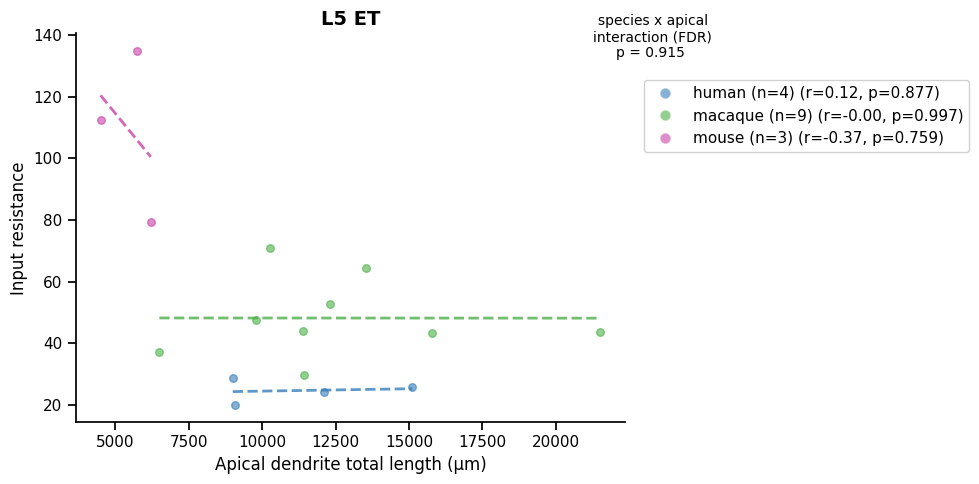

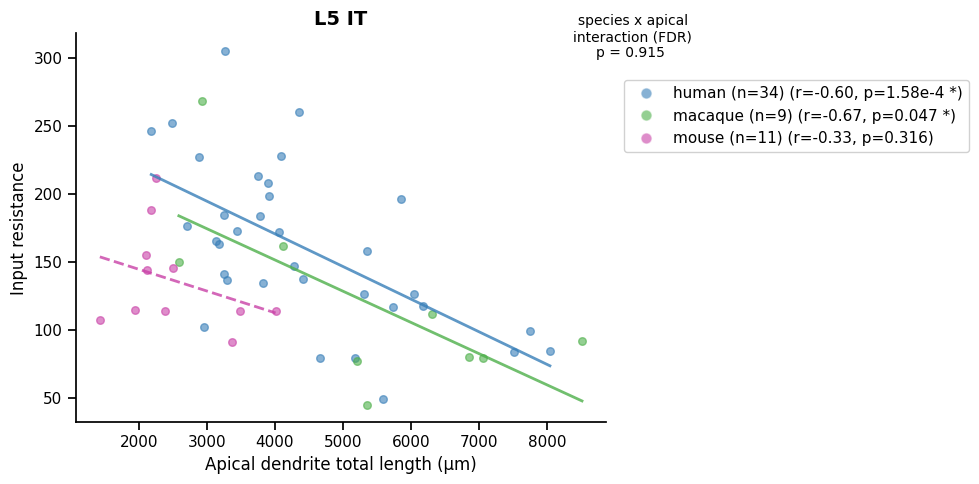

Saved apical dendrite plots to /root/capsule/scratch/20260807/species_comparison/species_input_resistance_vs_apical_length_by_species.pdf


In [12]:
if apical_results is not None:
    fig_path = OUT_DIR / f'{species_type}_input_resistance_vs_apical_length_by_species.pdf'
    
    with PdfPages(fig_path) as pdf:
        for _, row in apical_results.iterrows():
            subclass = row['subclass']
            
            fig, ax = plt.subplots(figsize=(10, 5))
            
            plot_species_interaction_scatter(
                data=data,
                dendrite_col='apical_dendrite_total_length',
                response_var=input_resistance_col,
                subclass=subclass,
                stats_row=row,
                species_col='species',
                species_colors=species_colors,
                ax=ax
            )
            
            plt.tight_layout()
            pdf.savefig(fig, bbox_inches='tight')
            plt.show()
            plt.close()
    
    print(f"Saved apical dendrite plots to {fig_path}")
else:
    print("No apical dendrite results to plot")

### Basal Dendrite Plots

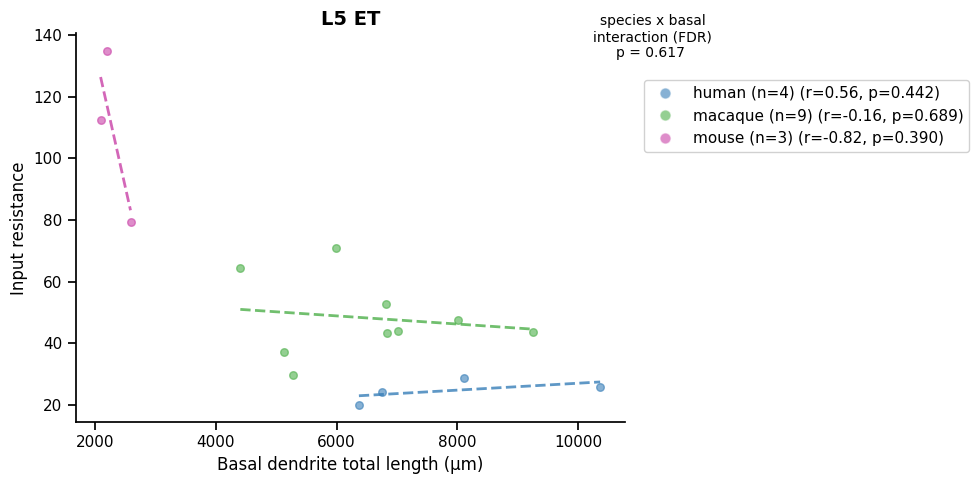

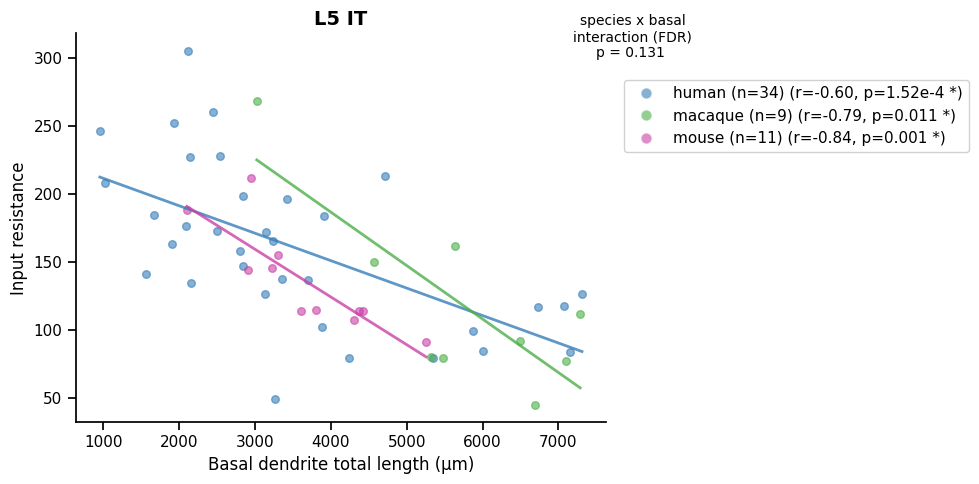

Saved basal dendrite plots to /root/capsule/scratch/20260807/species_comparison/species_input_resistance_vs_basal_length_by_species.pdf


In [13]:
if basal_results is not None:
    fig_path = OUT_DIR / f'{species_type}_input_resistance_vs_basal_length_by_species.pdf'
    
    with PdfPages(fig_path) as pdf:
        for _, row in basal_results.iterrows():
            subclass = row['subclass']
            
            fig, ax = plt.subplots(figsize=(10, 5))
            
            plot_species_interaction_scatter(
                data=data,
                dendrite_col='basal_dendrite_total_length',
                response_var=input_resistance_col,
                subclass=subclass,
                stats_row=row,
                species_col='species',
                species_colors=species_colors,
                ax=ax
            )
            
            plt.tight_layout()
            pdf.savefig(fig, bbox_inches='tight')
            plt.show()
            plt.close()
    
    print(f"Saved basal dendrite plots to {fig_path}")
else:
    print("No basal dendrite results to plot")

### Summary Heatmap

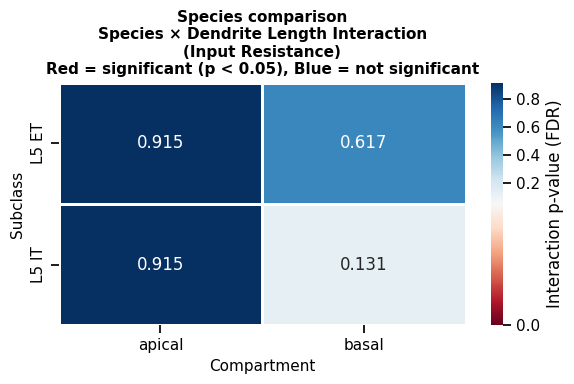

Saved summary heatmap to /root/capsule/scratch/20260807/species_comparison/species_input_resistance_dendrite_interaction_summary.pdf


In [14]:
# Create summary heatmap of interaction p-values
if apical_results is not None or basal_results is not None:
    # Combine results
    all_results = []
    if apical_results is not None:
        all_results.append(apical_results)
    if basal_results is not None:
        all_results.append(basal_results)
    
    combined_results = pd.concat(all_results, ignore_index=True)
    
    # Create pivot table for heatmap
    pivot_data = combined_results.pivot(
        index='subclass',
        columns='compartment',
        values='interaction_pval_fdr'
    )
    
    fig, ax = plt.subplots(figsize=(6, 4))
    
    # Use RdBu colormap centered at 0.05
    # Red = significant (p < 0.05), Blue = not significant (p > 0.05)
    import matplotlib.colors as mcolors
    
    # Create a diverging colormap centered at 0.05
    # vmin=0, vmax=0.1 (or adapt based on data), center=0.05
    vmin = 0
    vmax = max(0.1, pivot_data.max().max())  # At least 0.1, or max p-value
    
    # Create custom normalization centered at 0.05
    divnorm = mcolors.TwoSlopeNorm(vmin=vmin, vcenter=0.05, vmax=vmax)
    
    sns.heatmap(
        pivot_data,
        annot=pivot_data.applymap(lambda x: f"{x:.3g}" if not pd.isna(x) else "N/A"),
        fmt='',
        cmap='RdBu',  # Red=low p-value (significant), Blue=high p-value (not significant)
        norm=divnorm,
        cbar_kws={'label': 'Interaction p-value (FDR)'},
        linewidths=1,
        linecolor='white',
        ax=ax
    )
    
    ax.set_title(
        f"{species_type.capitalize()} comparison\nSpecies × Dendrite Length Interaction\n(Input Resistance)\nRed = significant (p < 0.05), Blue = not significant",
        fontsize=11,
        fontweight='bold'
    )
    ax.set_xlabel('Compartment', fontsize=11)
    ax.set_ylabel('Subclass', fontsize=11)
    
    plt.tight_layout()
    fig_path = OUT_DIR / f'{species_type}_input_resistance_dendrite_interaction_summary.pdf'
    plt.savefig(fig_path, bbox_inches='tight')
    plt.show()
    
    print(f"Saved summary heatmap to {fig_path}")

## Save Results

In [15]:
# Combine and save all statistics
if apical_results is not None or basal_results is not None:
    all_results = []
    if apical_results is not None:
        all_results.append(apical_results)
    if basal_results is not None:
        all_results.append(basal_results)
    
    combined_results = pd.concat(all_results, ignore_index=True)
    
    # Save statistics
    stats_path = OUT_DIR / f'{species_type}_input_resistance_dendrite_interaction_stats.csv'
    combined_results.to_csv(stats_path, index=False)
    print(f"Saved statistics to {stats_path}")
    
    # Save merged data
    data_path = OUT_DIR / f'{species_type}_input_resistance_dendrite_merged_data.csv'
    data.to_csv(data_path, index=False)
    print(f"Saved merged data to {data_path}")
else:
    print("No results to save")

Saved statistics to /root/capsule/scratch/20260807/species_comparison/species_input_resistance_dendrite_interaction_stats.csv
Saved merged data to /root/capsule/scratch/20260807/species_comparison/species_input_resistance_dendrite_merged_data.csv
